# Issue #373 — corrected N7 R3 support-transfer count grid

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n7_support_transfer_grid'

In [2]:
dev=pd.read_csv(OUT/'development_diagnostic_gate.csv')
dev

,base,diagnostic,conditioning,rows,mean_score,observed_rate,bin_spearman,nonnegative_monotonicity
0,R0_CORRECTED,contraction_score,SUPPORTED_REALIZED,1427,0.707281,0.710582,0.705170,True
1,R0_CORRECTED,expansion_score,ALL,1781,0.166266,0.198765,0.911858,True
2,R3_CORRECTED,contraction_score,SUPPORTED_REALIZED,1410,0.721945,0.718440,0.826752,True
3,R3_CORRECTED,expansion_score,ALL,1781,0.185926,0.208310,0.866667,True


In [3]:
perf=pd.read_csv(OUT/'performance.csv')
perf[perf.scope.eq('ALL')]

,scope,cell,contraction_count,expansion_count,issues,ticket_count_per_issue,total_tickets,ticket_hit_rate,issue_gross_positive_rate,issue_profitable_rate,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,conditional_gross_on_hit_cny,ex_largest_pnl_cny,ideal_fractional_pnl_cny,integer_minus_ideal_cny
36,ALL,C0E0,0,0,151,128,19328,0.001345,0.172185,0.158940,154624.0,187313.126230,32689.126230,132689.126230,0.326891,0.211410,7204.351009,-27225.255881,32689.126230,0.000000
37,ALL,C0E1,0,1,151,192,28992,0.001345,0.258278,0.198675,154624.0,176846.847126,22222.847126,122222.847126,0.222228,0.143722,4534.534542,-22456.939457,23490.110233,-1267.263107
38,ALL,C0E2,0,2,151,288,43488,0.001242,0.357616,0.238411,154624.0,171646.795189,17022.795189,117022.795189,0.170228,0.110092,3178.644355,-12422.395867,5289.266825,11733.528364
39,ALL,C0E3,0,3,151,432,65232,0.001012,0.437086,0.251656,154624.0,151397.750178,-3226.249822,96773.750178,-0.032262,-0.020865,2293.905306,-18961.830101,-8944.879211,5718.629389
40,ALL,C1E0,1,0,151,64,9664,0.001966,0.125828,0.119205,154624.0,170614.638344,15990.638344,115990.638344,0.159906,0.103416,8979.717808,-19949.995657,15990.638344,0.000000
41,ALL,C1E1,1,1,151,96,14496,0.002070,0.198675,0.185430,154624.0,207537.150711,52913.150711,152913.150711,0.529132,0.342205,6917.905024,12038.200012,57333.518969,-4420.368258
42,ALL,C1E2,1,2,151,144,21744,0.001886,0.271523,0.245033,154624.0,193883.000090,39259.000090,139259.000090,0.392590,0.253900,4728.853661,6763.839531,31557.741591,7701.258499
43,ALL,C1E3,1,3,151,216,32616,0.001564,0.337748,0.284768,154624.0,187421.518650,32797.518650,132797.518650,0.327975,0.212111,3674.931738,8546.942617,33740.938740,-943.420090
44,ALL,C2E0,2,0,151,32,4832,0.002070,0.066225,0.066225,154624.0,121578.401029,-33045.598971,66954.401029,-0.330456,-0.213716,12157.840103,-68602.782985,-33045.598971,0.000000
45,ALL,C2E1,2,1,151,48,7248,0.002483,0.119205,0.119205,154624.0,142213.504237,-12410.495763,87589.504237,-0.124105,-0.080262,7900.750235,-34249.735771,-10970.887986,-1439.607776


In [4]:
annual=perf[perf.scope.ne('ALL')].pivot(index='cell',columns='scope',values='pnl_cny')
annual

scope,2022,2023,2024
cell,,,
C0E0,-27806.981139,39021.815382,21474.291987
C0E1,-25644.191315,20275.374504,27591.663938
C0E2,-10885.787286,14896.317946,13012.264529
C0E3,-5919.931187,4444.489238,-1750.807873
C1E0,-21729.297009,-8085.308377,45805.243730
C1E1,-13532.770340,-11970.297991,78416.219042
C1E2,-13486.680779,-3643.892935,56389.573804
C1E3,-9795.617292,17292.922328,25300.213614
C2E0,-52224.000000,19517.682440,-339.281411


In [5]:
risk=pd.read_csv(OUT/'risk_diagnostics.csv')
runs=pd.read_csv(OUT/'losing_run_diagnostics.csv')
risk[risk.scope.eq('ALL')].merge(runs[runs.scope.eq('ALL')],on=['scope','cell'])

,scope,cell,max_drawdown_fraction,longest_profitable_issue_losing_run,open_underwater_issues,largest_payout_share,payout_hhi,losing_run_count,longest_run,median_run,p75_run,p90_run,runs_ge_10,runs_ge_15
0,ALL,C0E0,0.331650,19,1,0.325329,0.136820,20,19,4.0,7.50,18.0,4,4
1,ALL,C0E1,0.316968,22,1,0.258437,0.096493,21,22,4.0,7.00,14.0,4,2
2,ALL,C0E2,0.217738,11,4,0.177511,0.059839,30,11,2.5,6.00,8.1,1,0
3,ALL,C0E3,0.208717,9,95,0.110699,0.046024,36,9,2.5,4.00,6.0,0,0
4,ALL,C1E0,0.500756,31,1,0.216656,0.097748,17,31,4.0,7.00,21.8,4,4
5,ALL,C1E1,0.373446,22,0,0.201887,0.080013,19,22,4.0,7.50,15.6,4,3
6,ALL,C1E2,0.308025,15,8,0.172883,0.062087,27,15,3.0,5.00,7.8,2,1
7,ALL,C1E3,0.218967,7,8,0.134854,0.049179,35,7,3.0,4.00,6.0,0,0
8,ALL,C2E0,0.782095,53,151,0.300886,0.182557,10,53,8.0,21.75,26.9,5,4
9,ALL,C2E1,0.662223,50,151,0.160767,0.092582,13,50,4.0,11.00,20.6,5,3


In [6]:
lift=pd.read_csv(OUT/'moving_block_lift_bootstrap.csv')
lift[lift.scope.eq('ALL')]

,scope,cell,issues,matched_lift_cny,ideal_fractional_matched_lift_cny,integer_contribution_to_lift_cny,largest_abs_delta_issue,largest_abs_delta_cny,ex_largest_lift_cny,block_length,draws,lift_p05_cny,lift_median_cny,lift_p95_cny,ideal_lift_p05_cny,ideal_lift_median_cny,ideal_lift_p95_cny
33,ALL,C0E1,151,-10466.279103,-9199.015996,-1267.263107,24104,16759.580280,-27225.859383,10,5000,-47952.406226,-11137.112636,26377.783402,-57213.457564,-10275.532241,38501.062200
34,ALL,C0E2,151,-15666.331041,-27399.859405,11733.528364,23021,-30469.191055,14802.860015,10,5000,-88265.975697,-12858.576854,51520.775827,-101272.155865,-24165.693943,39375.961114
35,ALL,C0E3,151,-35915.376051,-41634.005441,5718.629389,23021,-45703.786583,9788.410532,10,5000,-139592.299280,-32873.181011,53669.702811,-136663.201671,-39046.799252,40558.413306
36,ALL,C1E0,151,-16698.487885,-16698.487885,0.000000,23021,-60938.382111,44239.894226,10,5000,-146877.492636,-11050.594034,79774.599805,-146877.492636,-11050.594034,79774.599805
37,ALL,C1E1,151,20224.024481,24644.392739,-4420.368258,23021,-60938.382111,81162.406592,10,5000,-111987.482981,28029.333983,130659.222742,-110208.835978,32645.164346,138803.476671
38,ALL,C1E2,151,6569.873861,-1131.384639,7701.258499,23021,-60938.382111,67508.255972,10,5000,-122821.671663,14866.196408,112168.772696,-129012.638299,7655.123399,101051.296387
39,ALL,C1E3,151,108.392421,1051.812510,-943.420090,23021,-60938.382111,61046.774532,10,5000,-135691.061119,5111.584277,111032.941334,-134021.944259,6084.230925,109288.529255
40,ALL,C2E0,151,-65734.725201,-65734.725201,0.000000,23021,-60938.382111,-4796.343090,10,5000,-207383.037192,-63377.494385,60813.847478,-207383.037192,-63377.494385,60813.847478
41,ALL,C2E1,151,-45099.621992,-43660.014216,-1439.607776,23021,-60938.382111,15838.760119,10,5000,-175513.910126,-40459.778225,71189.983048,-175782.087981,-39429.153207,74654.907047
42,ALL,C2E2,151,-56801.208738,-55825.308435,-975.900303,23021,-60938.382111,4137.173373,10,5000,-182641.101543,-53965.020339,53645.575188,-181929.679688,-53050.710157,55592.405994


In [7]:
path_boot=pd.read_csv(OUT/'moving_block_path_bootstrap.csv')
path_boot[path_boot.scope.eq('ALL')]

,scope,cell,issues,block_length,draws,longest_run_p05,longest_run_median,longest_run_p95,max_drawdown_fraction_p05,max_drawdown_fraction_median,max_drawdown_fraction_p95,open_underwater_issues_p05,open_underwater_issues_median,open_underwater_issues_p95
36,ALL,C0E0,151,10,5000,14.0,22.0,39.0,0.131011,0.306957,0.699068,1.0,52.5,151.0
37,ALL,C0E1,151,10,5000,12.0,20.0,34.0,0.126072,0.289848,0.647107,1.0,57.0,151.0
38,ALL,C0E2,151,10,5000,9.0,12.0,18.0,0.107802,0.219598,0.466280,1.0,52.0,150.0
39,ALL,C0E3,151,10,5000,7.0,10.0,14.0,0.121550,0.247016,0.467790,4.0,99.0,151.0
40,ALL,C1E0,151,10,5000,17.0,29.0,52.0,0.145484,0.321273,0.707913,2.0,56.0,151.0
41,ALL,C1E1,151,10,5000,13.0,21.0,36.0,0.103918,0.229334,0.523251,1.0,31.0,145.0
42,ALL,C1E2,151,10,5000,9.0,13.5,22.0,0.092159,0.184833,0.403929,0.0,30.0,145.0
43,ALL,C1E3,151,10,5000,7.0,9.0,12.0,0.087892,0.164517,0.334132,0.0,24.0,139.0
44,ALL,C2E0,151,10,5000,25.0,43.0,77.0,0.261847,0.615471,1.171396,11.0,128.0,151.0
45,ALL,C2E1,151,10,5000,20.0,32.0,57.0,0.195043,0.449494,0.900067,5.0,111.0,151.0


In [8]:
rolling=pd.read_csv(OUT/'rolling_windows.csv')
rolling

,cell,window_issues,windows,worst_window_pnl_cny,p10_window_pnl_cny,median_window_pnl_cny,positive_window_rate
0,C0E0,20,132,-18590.676002,-16084.179844,-7953.967711,0.333333
1,C0E0,30,122,-26404.359797,-23748.764547,-9736.944812,0.442623
2,C0E0,50,102,-31484.806254,-26782.981139,25570.291987,0.627451
3,C0E1,20,132,-19535.338001,-14425.667104,-5174.352421,0.333333
4,C0E1,30,122,-23328.033842,-19355.881441,-8716.473133,0.434426
5,C0E1,50,102,-32020.665712,-24618.924334,16548.475512,0.607843
6,C0E2,20,132,-15922.990395,-12558.174022,1262.353971,0.553030
7,C0E2,30,122,-17307.247319,-12341.842087,-459.076591,0.475410
8,C0E2,50,102,-15174.061375,-9859.343592,10689.037980,0.617647
9,C0E3,20,132,-11539.228459,-8148.600255,-696.642883,0.484848


In [9]:
pareto=pd.read_csv(OUT/'pareto_frontier.csv')
gate=pd.read_csv(OUT/'historical_gate.csv')
pareto[['cell','pnl_cny','max_drawdown_fraction','longest_profitable_issue_losing_run','pareto']]

,cell,pnl_cny,max_drawdown_fraction,longest_profitable_issue_losing_run,pareto
0,C0E0,32689.126230,0.331650,19,True
1,C0E1,22222.847126,0.316968,22,True
2,C0E2,17022.795189,0.217738,11,True
3,C0E3,-3226.249822,0.208717,9,True
4,C1E0,15990.638344,0.500756,31,False
5,C1E1,52913.150711,0.373446,22,True
6,C1E2,39259.000090,0.308025,15,True
7,C1E3,32797.518650,0.218967,7,True
8,C2E0,-33045.598971,0.782095,53,False
9,C2E1,-12410.495763,0.662223,50,False


In [10]:
gate

,cell,standalone_positive,standalone_ex_largest_positive,matched_lift_positive,matched_ex_largest_positive,moving_block_lift_p05_nonnegative,drawdown_no_worse_than_control,losing_run_no_worse_than_19,two_positive_annual_pnl,two_positive_annual_lifts,development_diagnostics_valid,control_keysets_valid,historical_gate_pass,expert_admitted,future_frozen_candidate_required
0,C0E1,True,False,False,False,False,True,False,True,True,True,True,False,False,False
1,C0E2,True,False,False,True,False,True,True,True,False,True,True,False,False,False
2,C0E3,False,False,False,True,False,True,True,False,False,True,True,False,False,False
3,C1E0,True,False,False,True,False,False,False,False,True,True,True,False,False,False
4,C1E1,True,True,True,True,False,False,False,False,True,True,True,False,False,False
5,C1E2,True,True,True,True,False,True,True,False,True,True,True,False,False,False
6,C1E3,True,True,True,True,False,True,True,True,True,True,True,False,False,False
7,C2E0,False,False,False,False,False,False,False,False,False,True,True,False,False,False
8,C2E1,False,False,False,True,False,False,False,True,False,True,True,False,False,False
9,C2E2,False,False,False,True,False,False,False,False,False,True,True,False,False,False


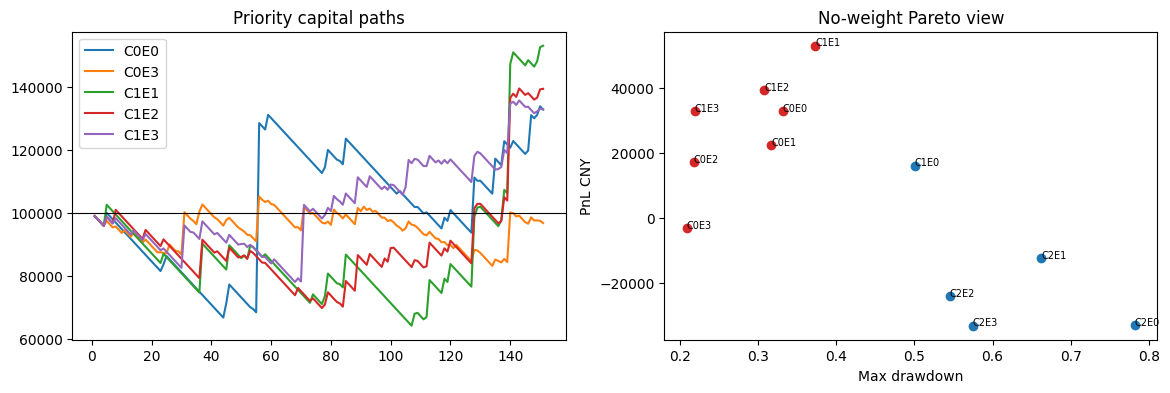

In [11]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4))
keep=['C0E0','C1E1','C1E2','C1E3','C0E3']
for cell,g in paths[(paths.scope=='ALL') & paths.cell.isin(keep)].groupby('cell'):
    axes[0].plot(g.issue_order,g.capital_cny,label=cell)
axes[0].axhline(100000,color='black',lw=.8); axes[0].legend(); axes[0].set_title('Priority capital paths')
for _,r in pareto.iterrows():
    axes[1].scatter(r.max_drawdown_fraction,r.pnl_cny,color=('tab:red' if r.pareto else 'tab:blue'))
    axes[1].annotate(r.cell,(r.max_drawdown_fraction,r.pnl_cny),fontsize=7)
axes[1].set_xlabel('Max drawdown'); axes[1].set_ylabel('PnL CNY'); axes[1].set_title('No-weight Pareto view'); plt.show()